# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170377
NAME = "Ekmanjot Kaur"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170377   Name: Ekmanjot Kaur   Fingerprint: FFA5C123   Tickets: 14

Ticket_ID                                                                               Ticket_Text
      T01                                                     I need Windows 11 by 5.30 p.m. today.
      T02 Projector keeps disconnecting before the assignment deadline. I have tried several times!
      T03            Python is not working after resetting my password. I have tried several times!
      T04                Projector is showing an error on my laptop. The same problem occurs again.
      T05                          The laptop crashes while opening. The same problem occurs again.
      T06 Matlab has stopped syncing before the assignment deadline. The same problem occurs again.
      T07                               Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T08                     I cannot access the Matlab during the lab. Is there another solution?
      T09      

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
results=[]
for ticket in df["Ticket_Text"]:
  result=process_ticket(ticket)
  results.append(result)
table=[]
for i,result in enumerate(results):
  row={
      "Ticket_ID":df.iloc[i]["Ticket_ID"],
      "sentences":len(result["sentences"]),
      "tokens":len(result["tokens"]),
      "stopwords":len(result["stops"]),
      "punctuation":len(result["punct"]),
      "unique_tokens":len(set(result["tokens"])),
      "final_tokens":len(result["final"])
  }
  table.append(row)
result_df=pd.DataFrame(table)
result_df.head()

,Ticket_ID,sentences,tokens,stopwords,punctuation,unique_tokens,final_tokens
0,T01,1,9,2,1,9,6
1,T02,2,14,4,2,14,8
2,T03,2,15,6,2,15,7
3,T04,2,15,7,2,14,6
4,T05,2,12,5,2,10,5


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

pattern=r"\b[A-Za-z]{6,}\b"
number_pattern=r"\b\d+(?:\.\d+)+\b|\b\d+\b"
cap_pattern=r"\b[A-Z][A-Za-z]*\b"
vowel_pattern=r"\b[AEIOUaeiou][A-Za-z]*\b"
for ticket in df["Ticket_Text"]:
  matches=re.findall(pattern,ticket)
  num_matches=re.findall(number_pattern,ticket)
  cap_matches=re.findall(cap_pattern,ticket)
  vow_matches=re.findall(vowel_pattern,ticket)
  print(matches)
  print(num_matches)
  print(cap_matches)
  print(vow_matches)


['Windows']
['11', '5.30']
['I', 'Windows']
['I']
['Projector', 'disconnecting', 'before', 'assignment', 'deadline', 'several']
[]
['Projector', 'I']
['assignment', 'I']
['Python', 'working', 'resetting', 'password', 'several']
[]
['Python', 'I']
['is', 'after', 'I']
['Projector', 'showing', 'laptop', 'problem', 'occurs']
[]
['Projector', 'The']
['is', 'an', 'error', 'on', 'occurs', 'again']
['laptop', 'crashes', 'opening', 'problem', 'occurs']
[]
['The', 'The']
['opening', 'occurs', 'again']
['Matlab', 'stopped', 'syncing', 'before', 'assignment', 'deadline', 'problem', 'occurs']
[]
['Matlab', 'The']
['assignment', 'occurs', 'again']
['helpdesk', 'thapar', 'thapar']
[]
['Write']
['it', 'edu', 'or', 'edu', 'it']
['cannot', 'access', 'Matlab', 'during', 'another', 'solution']
[]
['I', 'Matlab', 'Is']
['I', 'access', 'Is', 'another']
['Nothing', 'nobody', 'replied']
[]
['Nothing']
['and']
['locked', 'server', 'uploading', 'worked', 'yesterday']
[]
['I', 'It']
['I', 'out', 'of', 'uploadin

In [7]:
# re.sub use
email_pattern=r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b"
url_pattern=r"https:?://\S+|www\.\S+"
phoneno_pattern=r"\+\d{1,3}(?:[-\s]?\d{5}){2}|\b\d{4}-\d{3}-\d{4}\b"
for ticket in df["Ticket_Text"]:
  text=re.sub(email_pattern,"<EMAIL>",ticket)
  text=re.sub(url_pattern,"<URL>",ticket)
  text=re.sub(phoneno_pattern,"<PHONE>",ticket)
  print(text)


I need Windows 11 by 5.30 p.m. today.
Projector keeps disconnecting before the assignment deadline. I have tried several times!
Python is not working after resetting my password. I have tried several times!
Projector is showing an error on my laptop. The same problem occurs again.
The laptop crashes while opening. The same problem occurs again.
Matlab has stopped syncing before the assignment deadline. The same problem occurs again.
Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
I cannot access the Matlab during the lab. Is there another solution?
Nothing works and nobody has replied.
I was locked out of the server while uploading the file. It worked yesterday.
Python is showing an error while uploading the file. Please resolve it.
The LMS says 'Not Submitted'.
The Matlab has stopped syncing. Please resolve it.
VPN crashes while opening when I use mobile hotspot. Is there another solution?


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 23 words are capitalized just because they start a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
from nltk.tokenize import RegexpTokenizer
pattern = r"https?://\S+|www\.\S+|[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}|\+\d{1,3}(?:[-\s]?\d{5}){2}|\d{4}-\d{3}-\d{4}|\d+(?:\.\d+)+|[A-Za-z]+(?:-[A-Za-z]+)+|[A-Za-z]+(?:'[A-Za-z]+)|[A-Za-z]+|\d+"
tokenizer=RegexpTokenizer(pattern)
def my_tokenize(text):
  return tokenizer.tokenize(text)
for line in TEST_LINES:
  print("CUSTOM TOKENIZER")
  print(my_tokenize(line))
  print("WORD TOKENIZER")
  print(word_tokenize(line))
  print("\n")
print("\n\n\n")
print("TICKET TOKENIZATION")
for ticket in df["Ticket_Text"]:

  print("CUSTOM TOKENIZER")
  print(my_tokenize(ticket))
  print("WORD TOKENIZER")
  print(word_tokenize(ticket))
  print("\n")


CUSTOM TOKENIZER
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
WORD TOKENIZER
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']


CUSTOM TOKENIZER
['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
WORD TOKENIZER
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']


CUSTOM TOKENIZER
['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5.30', 'p', 'm', "didn't", 'work']
WORD TOKENIZER
['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']






TICKET TOKENIZATION
CUSTOM TOKENIZER
['I', 'need', 'Windows', '11',

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Almost all of the tickets are tokenized differently because custom tokenizer preserves certain structures that word tokenizer does not.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
all_final=[]
for ticket in df["Ticket_Text"]:
  result=process_ticket(ticket)
  all_final.extend(result["final"])
unique_final_tokens=sorted(set(all_final))
print(unique_final_tokens)
from nltk.stem import PorterStemmer, LancasterStemmer,RegexpStemmer,WordNetLemmatizer
from nltk import pos_tag
porter=PorterStemmer()
lancaster=LancasterStemmer()
regex=RegexpStemmer(r'ing$')
wordnet=WordNetLemmatizer()
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return 'a'
    elif tag.startswith('V'):
        return 'v'
    elif tag.startswith('N'):
        return 'n'
    elif tag.startswith('R'):
        return 'r'
    else:
        return 'n'
tagged_words = pos_tag(unique_final_tokens)
comp=[]
for word,tag in tagged_words:
  pos=get_wordnet_pos(tag)
  comp.append({
      "word":word,
      "Porter":porter.stem(word),
      "Lancaster":lancaster.stem(word),
      "Regex":regex.stem(word),
      "Lemmatizer":wordnet.lemmatize(word,pos=pos)
  }
  )
comparison=pd.DataFrame(comp)
comparison

["'not", '11', '5.30', 'access', 'another', 'assignment', 'crashes', 'deadline', 'disconnecting', 'error', 'file', 'hotspot', 'it.helpdesk', 'keeps', 'lab', 'laptop', 'lms', 'locked', 'matlab', 'mobile', 'need', 'nobody', 'nothing', 'occurs', 'opening', 'p.m.', 'password', 'please', 'problem', 'projector', 'python', 'replied', 'resetting', 'resolve', 'says', 'server', 'several', 'showing', 'solution', 'stopped', 'submitted', 'syncing', 'thapar.edu', 'times', 'today', 'tried', 'uploading', 'use', 'visit', 'vpn', 'windows', 'worked', 'working', 'works', 'write', 'www.thapar.edu/it', 'yesterday']


,word,Porter,Lancaster,Regex,Lemmatizer
0,'not,'not,'not,'not,'not
1,11,11,11,11,11
2,5.30,5.30,5.30,5.30,5.30
3,access,access,access,access,access
4,another,anoth,anoth,another,another
5,assignment,assign,assign,assignment,assignment
6,crashes,crash,crash,crashes,crash
7,deadline,deadlin,deadlin,deadline,deadline
8,disconnecting,disconnect,disconnect,disconnect,disconnect
9,error,error,er,error,error


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* overstemming- error- er
understemming- uploading-uploading

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [10]:
# Your code
S1=[]
S2=[]
S3=[]
for ticket in df["Ticket_Text"]:
  result=process_ticket(ticket)
  S1.extend(result["tokens"])
  S2.extend([t for t in result["tokens"] if not is_punct(t)])
  S3.extend(result["final"])
S4=[porter.stem(t) for t in S3]
def corpus_stats(tokens):
  total=len(tokens)
  unique=len(set(tokens))
  ttr=total/unique
  return total, unique,ttr
for name,tokens in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
  total,unique,ttr=corpus_stats(tokens)
  print(name)
  print(f"Total tokens:{total}")
  print(f"Unique Tokens:{unique}")
  print(f"TTR:{ttr}")
  print()


S1
Total tokens:173
Unique Tokens:88
TTR:1.9659090909090908

S2
Total tokens:147
Unique Tokens:83
TTR:1.7710843373493976

S3
Total tokens:83
Unique Tokens:57
TTR:1.456140350877193

S4
Total tokens:83
Unique Tokens:55
TTR:1.509090909090909



Top 10 tokens S1:
[('.', 20), ('the', 13), ('i', 6), ('is', 5), ('while', 4), ('same', 3), ('problem', 3), ('occurs', 3), ('again', 3), ('matlab', 3)]

TOP 10 tokens S3:
[('problem', 3), ('occurs', 3), ('matlab', 3), ('projector', 2), ('assignment', 2), ('deadline', 2), ('tried', 2), ('several', 2), ('times', 2), ('python', 2)]


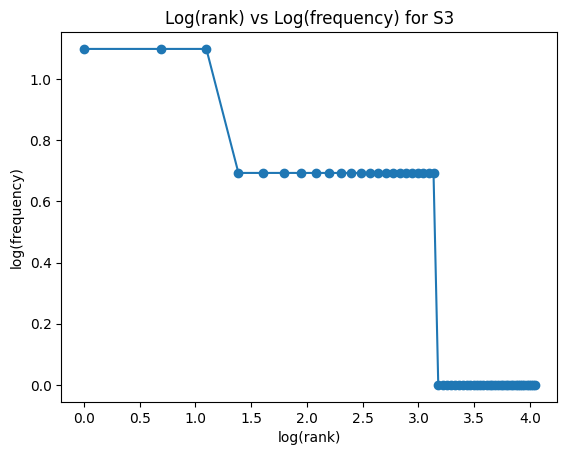

In [13]:
from collections import Counter
print("Top 10 tokens S1:")
print(Counter(S1).most_common(10))
print("\nTOP 10 tokens S3:")
print(Counter(S3).most_common(10))
freq=Counter(S3)
ranked=freq.most_common()
import math
import matplotlib.pyplot as plt
ranks=range(1,len(ranked)+1)
frequencies=[count for word, count in ranked]
log_ranks=[math.log(r) for r in ranks]
log_freq=[math.log(f) for f in frequencies]
plt.plot(log_ranks, log_freq,marker='o')
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(rank) vs Log(frequency) for S3")
plt.show()


In [14]:
from nltk.util import bigrams
print("Top 5 bigrams of S1:")
print(Counter(bigrams(S1)).most_common(5))
print("\nTop 5 bigrams of S3:")
print(Counter(bigrams(S2)).most_common(5))


Top 5 bigrams of S1:
[(('.', 'the'), 6), (('.', 'i'), 4), (('the', 'same'), 3), (('same', 'problem'), 3), (('problem', 'occurs'), 3)]

Top 5 bigrams of S3:
[(('the', 'same'), 3), (('same', 'problem'), 3), (('problem', 'occurs'), 3), (('occurs', 'again'), 3), (('before', 'the'), 2)]


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because preprocessing removes punctuation and stopwords, while Porter stemming further reduces lexical diversity by mapping different word forms to the same stem. Therefore, S4 generally has fewer unique tokens relative to its total tokens.

**Ques**. One example where stemming produces an undesirable result

*Ans* Lancaster Stemming: mobile-mobl
cuts of unnecessary letters and results in an unintelligible word.

**Ques** Give one example where POS-aware lemmatization preserves meaning better than stemming.

*Ans* (i) tried- try with lemmatizer, but tri- with porter/lancaster stemmer.